# PTM3D notebook 06: lunar polar cold traps and ice stability

This notebook starts from the two simulations of [tutorial 5](../05_lunar_polar_ice.md), one year
of temperatures on a 6.5 km region of the de Gerlache crater rim near the lunar south pole, made
from a public shape-from-shading DEM. It maps the maximum, mean and minimum temperature, the
surface cold traps of water and carbon dioxide, and the depth below which water ice is stable,
and it writes the per-face values to a table for use elsewhere.

The cold traps of a volatile are found after the run, from the maximum surface temperature. A
face is a cold trap if its maximum temperature over the year stays below the temperature at which
the volatile's sublimation loss over geologic time is negligible. Tutorial 5 uses 110 K for water
and 54 K for carbon dioxide. Any other volatile only needs its own threshold, and no new
simulation.

**Cost:** under a minute, once the two simulations exist.

**Needs:** the outputs of tutorial 5, `output/lunar_ice_degerlache_radoff` and
`output/lunar_ice_degerlache_coupled`. Making them takes the DEM download (1.3 GB), the LOLA
polar DEM (115 MB), and about half an hour of computing on eight cores. The first cell lists the commands if the
outputs are missing.

In [1]:
import csv
import numpy as np
from matplotlib.colors import ListedColormap
from ptm import paths, plots, Results

pre = paths.preflight([])
ROOT = pre.root
plt = plots.styled()

RUNS = {"off": ROOT / "output" / "lunar_ice_degerlache_radoff",
        "on": ROOT / "output" / "lunar_ice_degerlache_coupled"}
missing = [str(p.relative_to(ROOT)) for p in RUNS.values() if not (p / "statistics").is_dir()]
if missing:
    raise RuntimeError(
        "This notebook needs the two simulations of docs/tutorials/05_lunar_polar_ice.md. Follow its "
        "sections 'Data', 'The mesh' and 'The distant terrain', then run from the repository root\n"
        "    ./build/bin/ptm_thermal_sim --config examples/lunar_ice_degerlache_radoff.yaml\n"
        "    ./build/bin/ptm_thermal_sim --config examples/lunar_ice_degerlache_coupled.yaml\n"
        f"Missing: {', '.join(missing)}")
off, on = Results(RUNS["off"]), Results(RUNS["on"])
print(off)
print(on)

<Results lunar_ice_degerlache_radoff: 26253 faces, 0 per-step field(s), ? steps>
<Results lunar_ice_degerlache_coupled: 26253 faces, 0 per-step field(s), ? steps>


## 1. The region and its map coordinates

The mesh vertices are in meters in the Moon's body-fixed frame. For maps we project them onto a
south polar stereographic plane, $\rho = 2R \tan[(90^\circ + \phi)/2]$ for latitude $\phi$, with
$x = \rho \sin\lambda$ and $y = \rho \cos\lambda$ for longitude $\lambda$, and center the
coordinates on the region. Every map below draws the mesh triangles themselves, colored by face.

In [2]:
R = 1737.4                                     # km, the reference sphere of the DEM
v = off.mesh["vertices"] / 1000.0
lat = np.arcsin(v[:, 2] / np.linalg.norm(v, axis=1))
lon = np.arctan2(v[:, 1], v[:, 0])
rho = 2 * R * np.tan((np.pi / 2 + lat) / 2)
x, y = rho * np.sin(lon), rho * np.cos(lon)
x0, y0 = x.mean(), y.mean()
x, y = x - x0, y - y0
tris = off.mesh["faces"]
area = off.face_areas_m2

def draw(ax, values, **kwargs):
    art = ax.tripcolor(x, y, tris, facecolors=values, **kwargs)
    ax.set_aspect("equal")
    ax.set_xlabel("x (km)")
    return art

print(f"{off.n_faces} faces, total area {area.sum() / 1e6:.1f} km2, "
      f"latitudes {off.lat.min():.2f} to {off.lat.max():.2f} deg")

26253 faces, total area 136.8 km2, latitudes -88.89 to -88.46 deg


## 2. Maximum, mean and minimum temperature

The three statistics are taken over the one-year output window, after the spin-up. They are from
the run with radiation exchange, in which each face also receives the sunlight scattered and the
infrared emitted by the faces it sees.

temperature_max:   33.3 to  327.9 K, area-weighted mean  269.7 K
temperature_avg:   30.5 to  172.5 K, area-weighted mean  130.4 K
temperature_min:   29.0 to   81.6 K, area-weighted mean   67.6 K


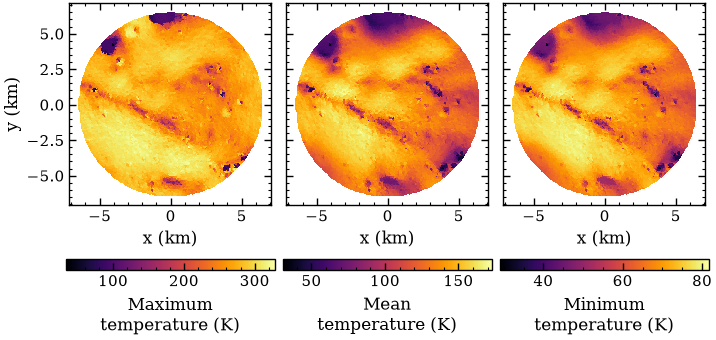

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(plots.DOUBLE_W, 3.4), sharey=True, constrained_layout=True)
for ax, moment, name in zip(axes, ("max", "avg", "min"), ("Maximum", "Mean", "Minimum")):
    art = draw(ax, on.stat("temperature", moment), cmap=plots.CMAP_TEMPERATURE)
    plots.colorbar(fig, art, ax, label=f"{name}\ntemperature (K)", location="bottom")
axes[0].set_ylabel("y (km)")
for moment in ("max", "avg", "min"):
    t = on.stat("temperature", moment)
    print(f"temperature_{moment}: {t.min():6.1f} to {t.max():6.1f} K, area-weighted mean "
          f"{np.average(t, weights=area):6.1f} K")

The maximum temperature is set by the few hours each year when the low Sun strikes a face most
directly. The minimum is reached when the Sun is lowest, and it is lowest in the permanently
shadowed floors, where only the infrared from the surrounding terrain and the internal heat flow
keep the surface warm.

## 3. Cold traps for water and carbon dioxide

A cold-trap map is a threshold on the maximum temperature. The function below returns the face
mask and the fraction of the area it covers. Comparing the two runs shows how much the
infrared emission of the sunlit terrain affects each volatile.

In [4]:
def cold_traps(run, threshold_k):
    mask = run.stat("temperature", "max") < threshold_k
    return mask, 100 * area[mask].sum() / area.sum()

THRESHOLDS = {"water": 110.0, "carbon dioxide": 54.0}
for label, run in (("radiation exchange off", off), ("radiation exchange on ", on)):
    parts = [f"{name} ({t:.0f} K) {cold_traps(run, t)[1]:.2f}%" for name, t in THRESHOLDS.items()]
    print(f"{label}: " + ",  ".join(parts))

radiation exchange off: water (110 K) 2.09%,  carbon dioxide (54 K) 1.98%
radiation exchange on : water (110 K) 1.90%,  carbon dioxide (54 K) 0.01%


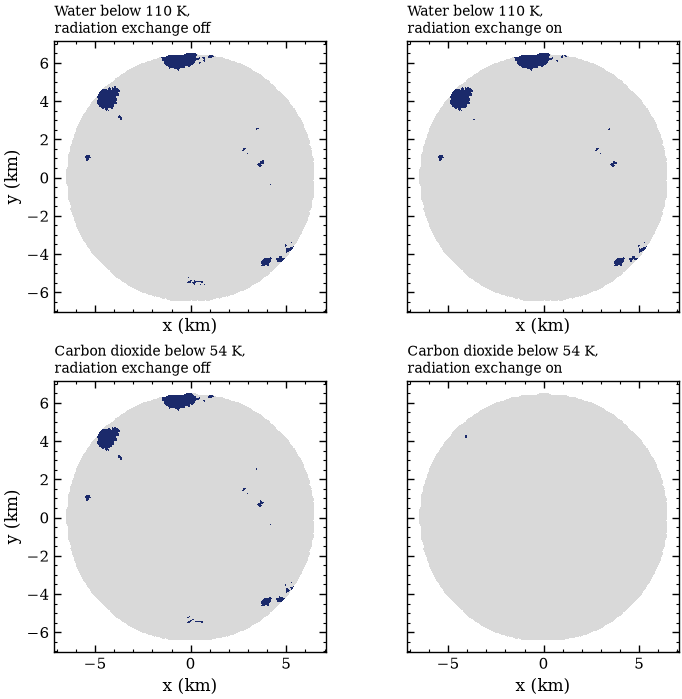

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(plots.DOUBLE_W, 7.0), sharex=True, sharey=True, constrained_layout=True)
trap_colors = ListedColormap(["#d9d9d9", "#1b2a6b"])
for row, (name, t) in enumerate(THRESHOLDS.items()):
    for col, (label, run) in enumerate((("radiation exchange off", off), ("radiation exchange on", on))):
        mask, pct = cold_traps(run, t)
        draw(axes[row, col], mask.astype(float), cmap=trap_colors, vmin=0, vmax=1)
        axes[row, col].set_title(f"{name.capitalize()} below {t:.0f} K,\n{label}", fontsize=10, loc="left")
for ax in axes[:, 0]:
    ax.set_ylabel("y (km)")

Dark faces are cold traps. The water cold traps are nearly the same in the two runs. The carbon
dioxide cold traps of the run without radiation exchange almost vanish when it is included,
because the permanently shadowed faces see warm terrain and their maximum temperature rises well
above 54 K. A carbon dioxide cold trap can only be identified with radiation exchange.

The next figure generalizes the two maps to every threshold, as the area below each temperature.

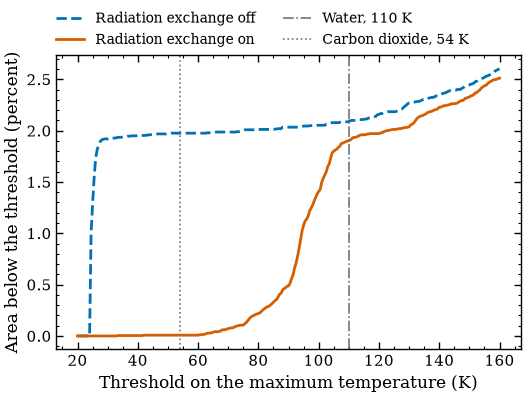

In [6]:
threshold = np.linspace(20, 160, 281)
fig, ax = plt.subplots(figsize=(plots.COLUMN_W * 1.5, 4.0), layout="constrained")
for run, kind, label in ((off, "radiation_off", "Radiation exchange off"),
                         (on, "radiation_on", "Radiation exchange on")):
    ax.plot(threshold, [cold_traps(run, t)[1] for t in threshold], **plots.STYLES[kind], label=label)
for (name, t), style in zip(THRESHOLDS.items(), ("-.", ":")):
    ax.axvline(t, color="0.45", lw=1.2, ls=style, label=f"{name.capitalize()}, {t:.0f} K")
ax.set_xlabel("Threshold on the maximum temperature (K)")
ax.set_ylabel("Area below the threshold (percent)")
fig.legend(loc="outside upper center", ncol=2);

## 4. Depth to stable water ice

Below the surface, water ice can be stable where the surface is too warm. The vapor that escapes
from buried ice must diffuse through the regolith above it, and the loss is small if the
temperature at the ice table is low enough. With `thermal.compute_ice_stability: true` the run
writes, for every face, the shallowest depth at which ice is stable,
`statistics/ice_depth.bin`. A value of 0 is a surface cold trap, and the bottom of the soil
column (0.47 m here) means that ice is not stable anywhere in the column. The calculation is for
water ice only. It is in the run without radiation exchange, whose spin-up is long enough for the
temperatures at depth to settle (tutorial 5, "Two simulations").

bottom of the column 0.47 m
ice stable within the column on 28.9% of the area, at the surface on 1.98%


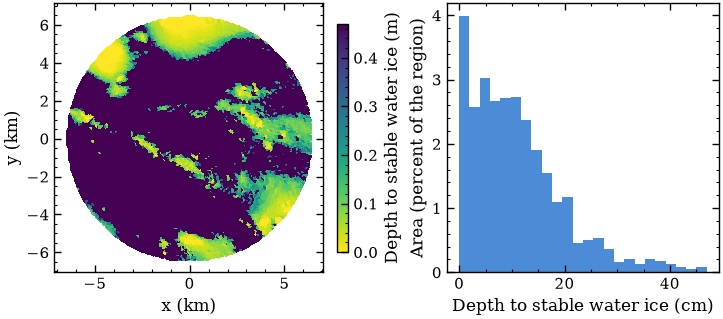

In [7]:
ice = off.stat("ice_depth", None)
bottom = ice.max()
fig, axes = plt.subplots(1, 2, figsize=(plots.DOUBLE_W, 3.2), constrained_layout=True)
art = draw(axes[0], ice, cmap=plots.CMAP_SCALAR + "_r")
fig.colorbar(art, ax=axes[0], shrink=0.85, label="Depth to stable water ice (m)")
axes[0].set_ylabel("y (km)")
stable = ice < bottom
axes[1].hist(100 * ice[stable], bins=24, weights=100 * area[stable] / area.sum(), color="#4c8bd6")
axes[1].set_xlabel("Depth to stable water ice (cm)")
axes[1].set_ylabel("Area (percent of the region)")
print(f"bottom of the column {bottom:.2f} m")
print(f"ice stable within the column on {100 * area[stable].sum() / area.sum():.1f}% of the area, "
      f"at the surface on {100 * area[ice == 0].sum() / area.sum():.2f}%")

The depth to stable ice is controlled mostly by the mean temperature of the ground, which sets
the vapor pressure at depth, and by the amplitude of the temperature cycle above it. The scatter
plot shows each face of the radiation-off run.

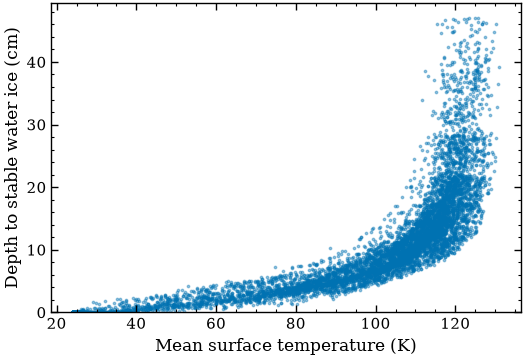

In [8]:
fig, ax = plt.subplots(figsize=(plots.COLUMN_W * 1.5, 3.6), constrained_layout=True)
ax.scatter(off.stat("temperature", "avg")[stable], 100 * ice[stable], s=3, alpha=0.4,
           color=plots.BLUE)
ax.set_xlabel("Mean surface temperature (K)")
ax.set_ylabel("Depth to stable water ice (cm)")
ax.set_ylim(bottom=0);

Ice is stable at the surface only on the permanently shadowed faces, whose mean temperature is
close to the geothermal floor. The ice table deepens steadily with the mean temperature, to about
10 cm at 100 K, and it leaves the 0.47 m column near 125 to 130 K. The spread at a given mean
temperature reflects the different amplitudes of the annual and diurnal cycles.

## 5. A table of the results

The per-face values can be written to a table for other software. The columns are the face index,
latitude and longitude, the map coordinates, the area, the three temperature statistics of both
runs and the ice depth.

In [9]:
table = ROOT / "output" / "lunar_ice_degerlache_faces.csv"
columns = {"tmax_off_K": off.stat("temperature", "max"), "tmax_on_K": on.stat("temperature", "max"),
           "tavg_on_K": on.stat("temperature", "avg"), "tmin_on_K": on.stat("temperature", "min"),
           "ice_depth_m": ice}
cx = (x[tris]).mean(axis=1)
cy = (y[tris]).mean(axis=1)
with open(table, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["face", "lat_deg", "lon_deg", "x_km", "y_km", "area_m2", *columns])
    for i in range(off.n_faces):
        w.writerow([i, f"{off.lat[i]:.5f}", f"{off.lon[i]:.5f}", f"{cx[i]:.4f}", f"{cy[i]:.4f}",
                    f"{area[i]:.2f}", *(f"{c[i]:.3f}" for c in columns.values())])
print(f"wrote {table.relative_to(ROOT)}: {off.n_faces} rows")

wrote output/lunar_ice_degerlache_faces.csv: 26253 rows


## 6. Exercises

1. Add another volatile to `THRESHOLDS` with a stability temperature from the literature, and
   map its cold traps in both runs.
2. The cold-trap area depends on the resolution of the mesh. Rebuild the core at a 50 m grid
   (`--downsample 10`, tutorial 5) and compare the curve of section 3.
3. With `thermal.thermal_b: 32` the soil column reaches 1.0 m. Rerun the radiation-off case and
   compare the ice-depth map. The spin-up estimate in the log gives the length the deeper column needs.